# Cartoonify — pure OpenCV pipeline

No machine learning at all in this one — the goal is a stylized cartoon-look version of an input image using only classical CV ops: bilateral filter to smooth color regions while keeping edges, an edge mask via adaptive thresholding on the grayscale, and a composite of the two.

I use a CIFAR-10 sample as the test image so the notebook is self-contained (no network image fetches). The upscaled 32x32 version is intentionally a hard input — if it still produces a recognizable stylized output, the pipeline is robust to low-res inputs.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision import datasets

np.random.seed(0)
DATA_ROOT = Path('../../data/torchvision_cache')
DATA_ROOT.mkdir(parents=True, exist_ok=True)

input: (256, 256, 3) uint8


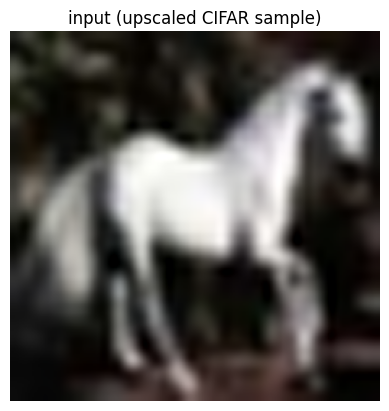

In [2]:
cifar = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
# pick something with a clear subject — frog, ship, horse tend to have continuous regions
candidate = next(i for i, t in enumerate(cifar.targets) if cifar.classes[t] == 'horse')
img_small = cifar.data[candidate]  # (32,32,3), uint8 RGB
img = cv2.resize(img_small, (256, 256), interpolation=cv2.INTER_CUBIC)
print('input:', img.shape, img.dtype)

plt.imshow(img); plt.axis('off'); plt.title('input (upscaled CIFAR sample)'); plt.show()

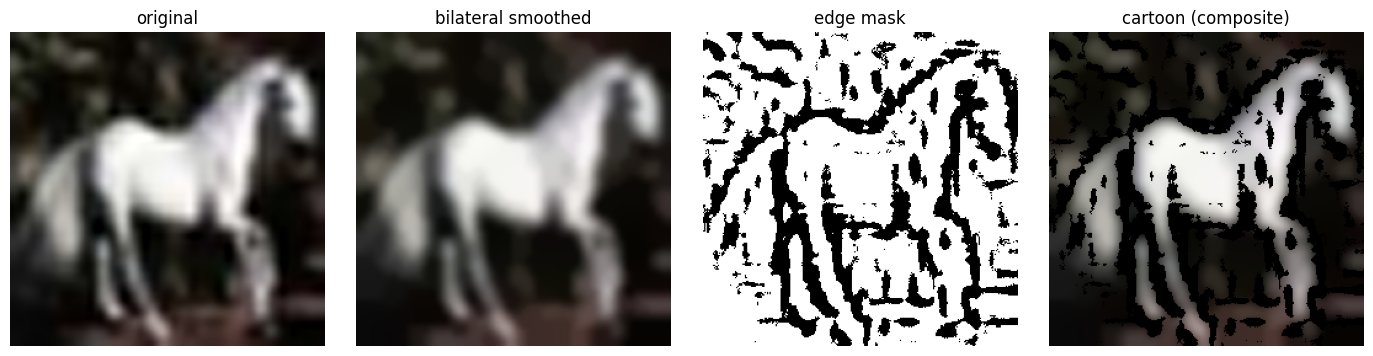

In [3]:
def cartoonify(rgb, num_down=2, num_bilateral=5, edge_blocksize=9, edge_C=2):
    img = rgb.copy()
    # 1) downscale, apply bilateral filter multiple times, upscale
    for _ in range(num_down):
        img = cv2.pyrDown(img)
    for _ in range(num_bilateral):
        img = cv2.bilateralFilter(img, d=7, sigmaColor=9, sigmaSpace=7)
    for _ in range(num_down):
        img = cv2.pyrUp(img)
    # resize back to match the original (pyrUp/Down may drift by a pixel)
    img = cv2.resize(img, (rgb.shape[1], rgb.shape[0]))
    # 2) edge mask
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    blur = cv2.medianBlur(gray, 5)
    edges = cv2.adaptiveThreshold(blur, 255,
                                  cv2.ADAPTIVE_THRESH_MEAN_C,
                                  cv2.THRESH_BINARY,
                                  edge_blocksize, edge_C)
    edges_rgb = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)
    # 3) combine
    cartoon = cv2.bitwise_and(img, edges_rgb)
    return img, edges, cartoon

smoothed, edges, cartoon = cartoonify(img)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(img); axes[0].set_title('original'); axes[0].axis('off')
axes[1].imshow(smoothed); axes[1].set_title('bilateral smoothed'); axes[1].axis('off')
axes[2].imshow(edges, cmap='gray'); axes[2].set_title('edge mask'); axes[2].axis('off')
axes[3].imshow(cartoon); axes[3].set_title('cartoon (composite)'); axes[3].axis('off')
plt.tight_layout(); plt.show()

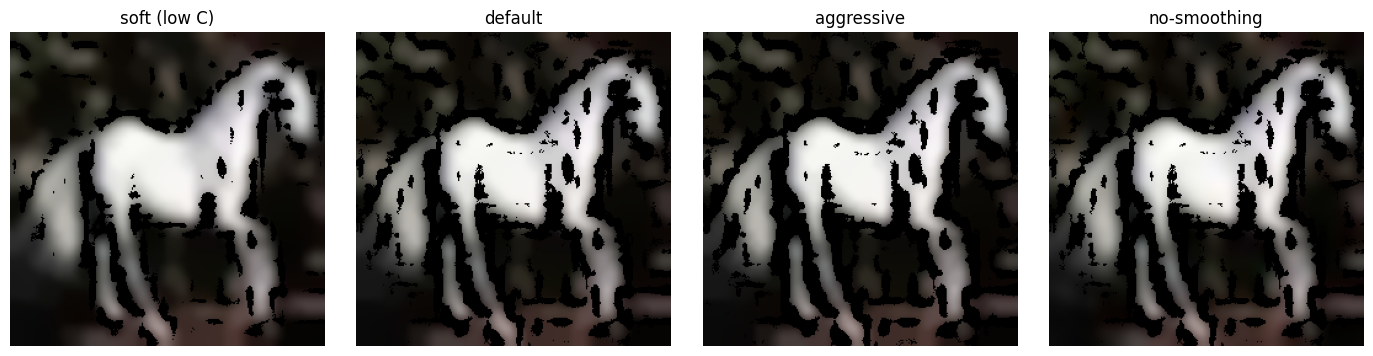

In [4]:
# Try a couple of parameter variations side-by-side
variants = {
    'soft (low C)':   cartoonify(img, num_bilateral=3, edge_blocksize=9, edge_C=4)[-1],
    'default':        cartoon,
    'aggressive':     cartoonify(img, num_bilateral=8, edge_blocksize=11, edge_C=2)[-1],
    'no-smoothing':   cartoonify(img, num_bilateral=0, edge_blocksize=9, edge_C=2)[-1],
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (name, im) in zip(axes, variants.items()):
    ax.imshow(im); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

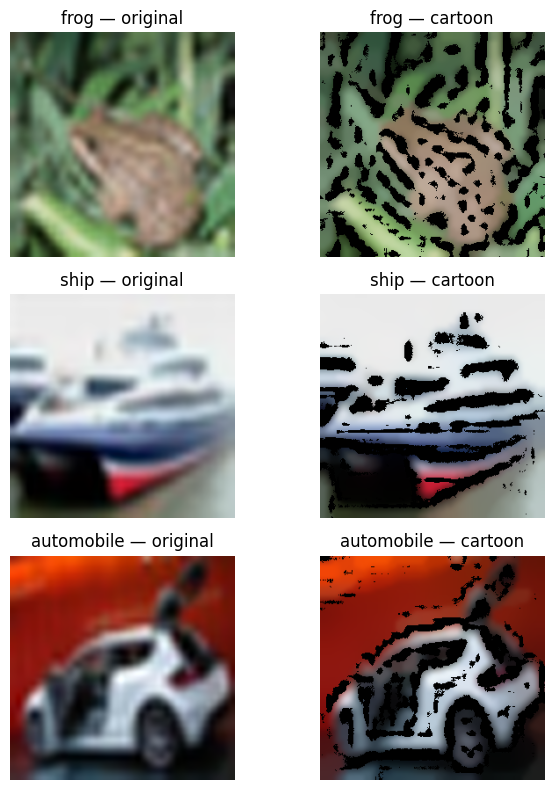

In [5]:
# Try a couple of other CIFAR classes too — frog and ship — to see how the pipeline handles different inputs
test_classes = ['frog', 'ship', 'automobile']
fig, axes = plt.subplots(len(test_classes), 2, figsize=(7, 8))
for row, cls in enumerate(test_classes):
    j = next(i for i, t in enumerate(cifar.targets) if cifar.classes[t] == cls)
    raw = cv2.resize(cifar.data[j], (256, 256), interpolation=cv2.INTER_CUBIC)
    _, _, c = cartoonify(raw)
    axes[row][0].imshow(raw); axes[row][0].set_title(f'{cls} — original'); axes[row][0].axis('off')
    axes[row][1].imshow(c);   axes[row][1].set_title(f'{cls} — cartoon');  axes[row][1].axis('off')
plt.tight_layout(); plt.show()

## Notes

Two parameters carry most of the visual style — the number of bilateral-filter passes and the adaptive-threshold `C` value. More bilateral passes flattens the colors more (more cartoonish, but loses detail). Higher `C` produces thinner / fewer edges, lower `C` produces a busier line drawing. The 'aggressive' variant tends to look the most cartoon-like to my eye but is also the least faithful.

Limitation worth being honest about: upscaling a 32x32 CIFAR sample isn't really a fair test of the pipeline. On a 1024x1024 photograph the bilateral filter would do a lot more lifting and the edges would line up properly with object boundaries. If I revisit this I'd point the same `cartoonify` at a self-supplied higher-res image and compare against a quick neural CartoonGAN baseline.